1. Реализуйте набор итераторов обхода по изображению. Рассмотрите возможность использования функции map и генератора данных для расчета индекса элемента изображения. Методы обхода:
* Линейный (построчный: последовательный перебор значений одной строки, второй и т.д.)
* Обход по спирали из центра изображения
* Алгоритм зиг-зага.
* Развертка Пеано

In [1]:
import numpy as np
from functools import wraps
from functools import partial
import random

In [21]:
# Итераторы

def lineal_iter(array2D: np.ndarray):
    if array2D.ndim != 2:
        raise ValueError("lineal_iter: массив должен быть 2-мерным!")
    a, b = array2D.shape
    for i in range(a):
        for j in range(b):
            yield i, j

In [22]:
def spiral_iter(array2D: np.ndarray):
    if array2D.ndim != 2:
        raise ValueError("spiral_iter: массив должен быть 2-мерным!")
    a, b = array2D.shape
    ci, cj = a // 2, b // 2          # центр
    i, j = ci, cj

    def inside(x, y):
        return 0 <= x < a and 0 <= y < b

    if inside(i, j):
        yield i, j

    # направления: вверх, влево, вниз, вправо (против часовой)
    dirs = [(-1, 0), (0, -1), (1, 0), (0, 1)]
    step_len = 1
    d = 0
    # максимальное число шагов, чтобы покрыть весь массив
    max_steps = 2 * max(a, b) + 2

    count = 1
    while count < a * b and max_steps > 0:
        for _ in range(2):                      # две стороны одной "рамки"
            dx, dy = dirs[d % 4]
            for _ in range(step_len):
                i += dx
                j += dy
                if inside(i, j):
                    yield i, j
                    count += 1
                    if count >= a * b:
                        return
            d += 1
        step_len += 1
        max_steps -= 1

In [23]:
def zigzag_iter(array2D: np.ndarray):
    if array2D.ndim != 2:
        raise ValueError("zigzag_scan_iter: массив должен быть 2-мерным!")

    a, b = array2D.shape
    # Проходим по всем возможным диагоналям (сумма индексов от 0 до a+b-2)
    for s in range(a + b - 1):
        if s % 2 == 0:
            # Четные диагонали: снизу вверх (i уменьшается, j увеличивается)
            # Ограничиваем i и j в пределах массива
            for i in range(min(s, a - 1), max(0, s - b + 1) - 1, -1):
                j = s - i
                yield i, j
        else:
            # Нечетные диагонали: сверху вниз (i увеличивается, j уменьшается)
            for i in range(max(0, s - b + 1), min(s, a - 1) + 1):
                j = s - i
                yield i, j

In [24]:
def peano_indices(n: int):
    # Вспомогательная функция для итератора
    if n <= 0 or (n & (n - 1)) != 0:
        raise ValueError("n должно быть степенью двойки")

    def recurse(s, x, y, dx, dy):
        if s == 1:
            yield x, y
            return
        half = s // 2

        yield from recurse(half, x,           y,           dy,  dx)
        yield from recurse(half, x + half*dx, y + half*dy, dx,  dy)
        yield from recurse(half, x + half*dx + half*dy, y + half*dy + half*dx, dx,  dy)
        yield from recurse(half, x + half*dy, y + half*dx, dy,  dx)

    yield from recurse(n, 0, 0, 1, 0)


def peano_iter(array2D: np.ndarray):
    if array2D.ndim != 2:
        raise ValueError("Массив должен быть 2-мерным!")

    a, b = array2D.shape
    n = max(a, b)

    # Если размер не степень двойки, дополняем его до ближайшей степени
    pow2 = 1
    while pow2 < n:
        pow2 <<= 1

    for r, c in peano_indices(pow2):
        if r < a and c < b:
            yield r, c

In [25]:
def iterator_test(indices_iter, shape):
    # возвращает матрицу нужного размера с порядком обхода
    order = np.full(shape, -1, dtype=np.int64)
    for k, (i, j) in enumerate(indices_iter(np.zeros(shape))):
        order[i, j] = k
    return order

In [165]:
a, b = 16, 16

In [166]:
print("LINEAR")
print(iterator_test(lineal_iter, (a, b)))
print()

LINEAR
[[  0   1   2   3   4   5   6   7   8   9  10  11  12  13  14  15]
 [ 16  17  18  19  20  21  22  23  24  25  26  27  28  29  30  31]
 [ 32  33  34  35  36  37  38  39  40  41  42  43  44  45  46  47]
 [ 48  49  50  51  52  53  54  55  56  57  58  59  60  61  62  63]
 [ 64  65  66  67  68  69  70  71  72  73  74  75  76  77  78  79]
 [ 80  81  82  83  84  85  86  87  88  89  90  91  92  93  94  95]
 [ 96  97  98  99 100 101 102 103 104 105 106 107 108 109 110 111]
 [112 113 114 115 116 117 118 119 120 121 122 123 124 125 126 127]
 [128 129 130 131 132 133 134 135 136 137 138 139 140 141 142 143]
 [144 145 146 147 148 149 150 151 152 153 154 155 156 157 158 159]
 [160 161 162 163 164 165 166 167 168 169 170 171 172 173 174 175]
 [176 177 178 179 180 181 182 183 184 185 186 187 188 189 190 191]
 [192 193 194 195 196 197 198 199 200 201 202 203 204 205 206 207]
 [208 209 210 211 212 213 214 215 216 217 218 219 220 221 222 223]
 [224 225 226 227 228 229 230 231 232 233 234 235 236 2

In [167]:
print("ZIG-ZAG")
print(iterator_test(zigzag_iter, (a, b)))
print()

ZIG-ZAG
[[  0   1   5   6  14  15  27  28  44  45  65  66  90  91 119 120]
 [  2   4   7  13  16  26  29  43  46  64  67  89  92 118 121 150]
 [  3   8  12  17  25  30  42  47  63  68  88  93 117 122 149 151]
 [  9  11  18  24  31  41  48  62  69  87  94 116 123 148 152 177]
 [ 10  19  23  32  40  49  61  70  86  95 115 124 147 153 176 178]
 [ 20  22  33  39  50  60  71  85  96 114 125 146 154 175 179 200]
 [ 21  34  38  51  59  72  84  97 113 126 145 155 174 180 199 201]
 [ 35  37  52  58  73  83  98 112 127 144 156 173 181 198 202 219]
 [ 36  53  57  74  82  99 111 128 143 157 172 182 197 203 218 220]
 [ 54  56  75  81 100 110 129 142 158 171 183 196 204 217 221 234]
 [ 55  76  80 101 109 130 141 159 170 184 195 205 216 222 233 235]
 [ 77  79 102 108 131 140 160 169 185 194 206 215 223 232 236 245]
 [ 78 103 107 132 139 161 168 186 193 207 214 224 231 237 244 246]
 [104 106 133 138 162 167 187 192 208 213 225 230 238 243 247 252]
 [105 134 137 163 166 188 191 209 212 226 229 239 242 

In [168]:
print("SPIRAL")
print(iterator_test(spiral_iter, (a, b)))
print()

SPIRAL
[[240 239 238 237 236 235 234 233 232 231 230 229 228 227 226 225]
 [241 182 181 180 179 178 177 176 175 174 173 172 171 170 169 224]
 [242 183 132 131 130 129 128 127 126 125 124 123 122 121 168 223]
 [243 184 133  90  89  88  87  86  85  84  83  82  81 120 167 222]
 [244 185 134  91  56  55  54  53  52  51  50  49  80 119 166 221]
 [245 186 135  92  57  30  29  28  27  26  25  48  79 118 165 220]
 [246 187 136  93  58  31  12  11  10   9  24  47  78 117 164 219]
 [247 188 137  94  59  32  13   2   1   8  23  46  77 116 163 218]
 [248 189 138  95  60  33  14   3   0   7  22  45  76 115 162 217]
 [249 190 139  96  61  34  15   4   5   6  21  44  75 114 161 216]
 [250 191 140  97  62  35  16  17  18  19  20  43  74 113 160 215]
 [251 192 141  98  63  36  37  38  39  40  41  42  73 112 159 214]
 [252 193 142  99  64  65  66  67  68  69  70  71  72 111 158 213]
 [253 194 143 100 101 102 103 104 105 106 107 108 109 110 157 212]
 [254 195 144 145 146 147 148 149 150 151 152 153 154 1

In [169]:
print("PEANO")
print(iterator_test(peano_iter,  (a, b)))
print()

PEANO
[[  0   1  12  13  16  19  20  21 192 193 204 205 208 211 212 213]
 [  3   2  15  14  17  18  23  22 195 194 207 206 209 210 215 214]
 [  4   7   8  11  28  31  24  25 196 199 200 203 220 223 216 217]
 [  5   6   9  10  29  30  27  26 197 198 201 202 221 222 219 218]
 [ 48  49  60  61  32  35  36  37 240 241 252 253 224 227 228 229]
 [ 51  50  63  62  33  34  39  38 243 242 255 254 225 226 231 230]
 [ 52  55  56  59  44  47  40  41 244 247 248 251 236 239 232 233]
 [ 53  54  57  58  45  46  43  42 245 246 249 250 237 238 235 234]
 [ 64  67  68  69 112 115 116 117 128 131 132 133 176 179 180 181]
 [ 65  66  71  70 113 114 119 118 129 130 135 134 177 178 183 182]
 [ 76  79  72  73 124 127 120 121 140 143 136 137 188 191 184 185]
 [ 77  78  75  74 125 126 123 122 141 142 139 138 189 190 187 186]
 [ 80  81  92  93  96  97 108 109 144 145 156 157 160 161 172 173]
 [ 83  82  95  94  99  98 111 110 147 146 159 158 163 162 175 174]
 [ 84  87  88  91 100 103 104 107 148 151 152 155 164 16

In [172]:
print("PEANO")
print(iterator_test(peano_iter,  (4, 4)))
print()

PEANO
1 0
0 1
1 0
1 0
0 1
[[ 0  1 12 13]
 [ 3  2 15 14]
 [ 4  7  8 11]
 [ 5  6  9 10]]



In [164]:
print(list(peano_indices(4)))

[(0, 0), (0, 1), (1, 1), (1, 0), (2, 0), (3, 0), (3, 1), (2, 1), (2, 2), (3, 2), (3, 3), (2, 3), (0, 2), (0, 3), (1, 3), (1, 2)]


2. Реализуйте конвертацию изображения в оттенки серого, используя лямбда-функции.

In [173]:
def rgb_to_gray(img: np.ndarray) -> np.ndarray:
    if img.ndim != 3 or img.shape[2] != 3:
        raise ValueError("rgb_to_gray: Ожидается RGB-изображение формы (H, W, 3)")

    gray_func = lambda pixel: int(0.299 * pixel[0] + 0.587 * pixel[1] + 0.114 * pixel[2])
    flat_gray = np.fromiter(
        map(gray_func, img.reshape(-1, 3)),
        dtype=np.uint8
    )

    # форма: (H, W)
    return flat_gray.reshape(img.shape[:2])

In [174]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

RGB: (243, 300, 3) -> Gray: (243, 300) uint8


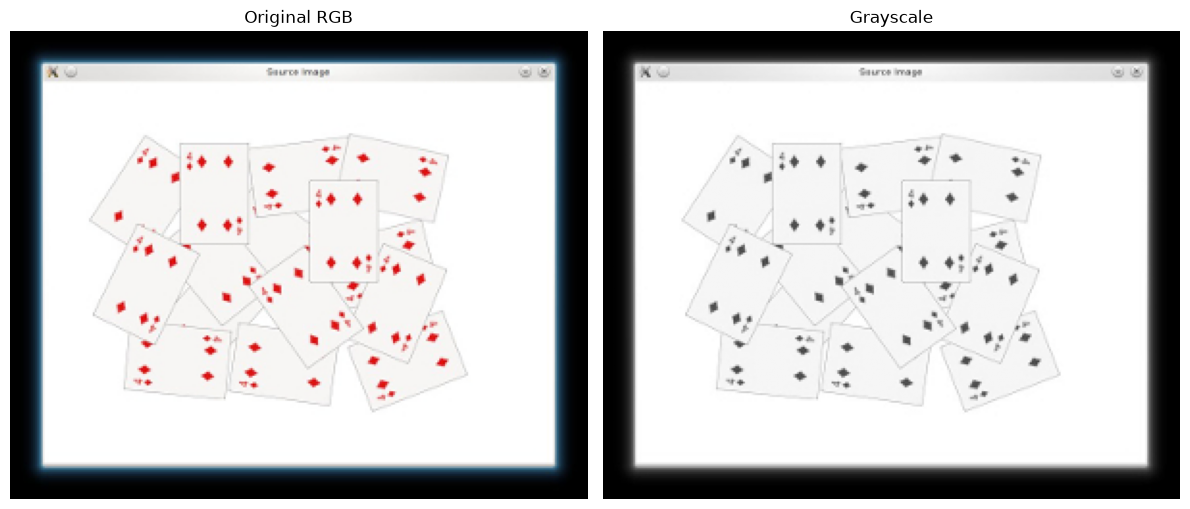

In [183]:
path = "color.jpeg"
img = cv2.imread(path)

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

gray = rgb_to_gray(img_rgb)
print("RGB:", img_rgb.shape, "-> Gray:", gray.shape, gray.dtype)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(img_rgb)
axes[0].set_title("Original RGB")
axes[0].axis("off")

axes[1].imshow(gray, cmap="gray", vmin=0, vmax=255)
axes[1].set_title("Grayscale")
axes[1].axis("off")

plt.tight_layout()
plt.show()

3. Реализуйте сверточный оператор, используя «ленивые» функции(ю). Пример возможных фильтров: двумерное усреднение, двумерный фильтр Гаусса (возможна реализации иного фильтра по окрестности, на Ваше усмотрение). Реализуйте общий вид фильтрации, фиксацию конкретных параметров фильтра реализуйте при помощи функции partial (частичное применение).

In [6]:
# Свёртка для 1 окна с центром в точке i, j
def conv_window(M, filter, i, j):
    n = len(filter)

    window = [row[j:j+n] for row in M[i:i+n]]
    ans = sum(window[a][b] * filter[a][b]
                    for a in range(n) for b in range(n))
    return ans

In [26]:
def conv_var_iter(iterator_func):
    #Декоратор для применения разных итераторов
    def wrapper(M, filter):
        H, W = len(M), len(M[0])
        s = len(filter)
        pad = s // 2

        s_h, s_w = H - s + 1, W - s + 1
        ans = [[0] * s_w for _ in range(s_h)]

        for r, c in iterator_func(np.zeros((H, W))):
            if r - pad < 0 or r + pad >= H or c - pad < 0 or c + pad >= W:
                continue

            val = conv_window(M, filter, r - pad, c - pad)
            ans[r - pad][c - pad] = val
        return ans

    return wrapper

4. Протестируйте реализованный алгоритм при применении различных алгоритмов обхода изображения. Убедитесь, что результат одинаков вне зависимости от порядка обхода. Для сравнения изображений возможно использовать метрику MSE. Применять фильтрацию необходимо для элементов изображения, при обработке которых не происходит выхода за границы данных.

In [27]:
# Ядро Гаусса 3x3 (нормализованное, сумма весов = 1)
gauss_kernel = [
    [1/16, 2/16, 1/16],
    [2/16, 4/16, 2/16],
    [1/16, 2/16, 1/16]
]

In [28]:
gaussian_filter_linear = partial(conv_var_iter(lineal_iter), filter=gauss_kernel)
gaussian_filter_spiral = partial(conv_var_iter(spiral_iter), filter=gauss_kernel)
gaussian_filter_zigzag = partial(conv_var_iter(zigzag_iter), filter=gauss_kernel)
gaussian_filter_peano = partial(conv_var_iter(peano_iter), filter=gauss_kernel)

In [29]:
def randomMat(M, N):
    return np.array([[random.uniform(0,1) for i in range(N)] for j in range(M)])

In [30]:
array2D = randomMat(50, 65)

ans1 = gaussian_filter_linear(array2D)
ans2 = gaussian_filter_spiral(array2D)
ans3 = gaussian_filter_zigzag(array2D)
ans4 = gaussian_filter_peano(array2D)

In [31]:
a1 = np.array(ans1)
a2 = np.array(ans2)
a3 = np.array(ans3)
a4 = np.array(ans4)

mse_2 = np.mean((a1 - a2) ** 2)
mse_3 = np.mean((a1 - a3) ** 2)
mse_4 = np.mean((a1 - a4) ** 2)

assert mse_2 < 1e-15, f"MSE для спирали слишком велико: {mse_2}"
assert mse_3 < 1e-15, f"MSE для зигзага слишком велико: {mse_3}"
assert mse_4 < 1e-15, f"MSE для Пеано слишком велико: {mse_4}"

print(f"MSE (Спираль): {mse_2:.2e}")
print(f"MSE (Зигзаг):  {mse_3:.2e}")
print(f"MSE (Пеано):   {mse_4:.2e}")
print("Все результаты идентичны!")

MSE (Спираль): 0.00e+00
MSE (Зигзаг):  0.00e+00
MSE (Пеано):   0.00e+00
Все результаты идентичны!
